## Хоккейные матчи

### (1) считываем

In [6]:
import pandas as pd

df = pd.read_excel("NHL-playoffs-2026.xlsx")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df.head(5)

,Dataset,Game ID,Date,Away Team,Home Team,Cumulated Away Score,Cumulated Home Score,Period,Elapsed Time,Remaining Time,...,Away Team's Player on the Ice #6,Away Team's Goalie,Home Team's Player on the Ice #1,Home Team's Player on the Ice #2,Home Team's Player on the Ice #3,Home Team's Player on the Ice #4,Home Team's Player on the Ice #5,Home Team's Player on the Ice #6,Home Team's Goalie,Home Team's Defending Side
0,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
1,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
2,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:13,19:47,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
3,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:14,19:46,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
4,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:19,19:41,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left


In [7]:
print(df.shape)
df.iloc[:10,[2,3,4,9,12]]

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


### (2) Сводная таблица по игре

В таблице должны быть дата, названия команд, сколько голов они забили и сколько
овертаймов понадобилось, если таковые были.

In [11]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Period"] = pd.to_numeric(df["Period"], errors="coerce")
df["Cumulated Away Score"] = pd.to_numeric(df["Cumulated Away Score"], errors="coerce")
df["Cumulated Home Score"] = pd.to_numeric(df["Cumulated Home Score"], errors="coerce")

# финальный счет игры - последнее непустое значение
def last_valid(series):
    s = series.dropna()
    return s.iloc[-1] if len(s) else pd.NA

games = (
    df.groupby("Game ID")
      .agg(
          Date=("Date", "first"),
          Away_Team=("Away Team", "first"),
          Home_Team=("Home Team", "first"),
          Away_Score=("Cumulated Away Score", last_valid),
          Home_Score=("Cumulated Home Score", last_valid),
          Max_Period=("Period", "max"),
      )
)

games["Away_Score"] = games["Away_Score"].astype("Int64")
games["Home_Score"] = games["Home_Score"].astype("Int64")

# метка итога: Final / Final/OT / Final/2OT ...
def outcome_label(p):
    if pd.isna(p):
        return "Final"
    ot = int(p) - 3
    if ot <= 0:
        return "Final"
    if ot == 1:
        return "Final/OT"
    return f"Final/{ot}OT"

games["Outcome"] = games["Max_Period"].apply(outcome_label)


print(games.iloc[-5:, -4:])

            Away_Score  Home_Score  Max_Period    Outcome
Game ID                                                  
2025030412           3           4           4   Final/OT
2025030413           4           5           5  Final/2OT
2025030414           5           3           3      Final
2025030415           2           4           3      Final
2025030416           3           0           3      Final


видим, что в файле внутри каждой игры события упорядочены по времени.
поэтому последняя строка игры = последнее по времени событие, и её кумулятивный счет и есть финальный счет матча

### (3) функция с инфо об игре

In [14]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (
        f"{g['Home_Team']} - {g['Away_Team']} "
        f"({g['Home_Score']} - {g['Away_Score']}, "
        f"{g['Outcome']}, {g['Date']:%Y-%m-%d})"
    )

In [15]:
print(gameInfo(games.index.min()))
# Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)

print(gameInfo(games.index.max()))
# Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


### (4) Сосчитайте, сколько всего было забито шайб в каждой игре (поля Away Score и HomeScoreв таблице matches) и выведите описательные статистики для этого показателя.

In [17]:
games["Total_Score"] = games["Away_Score"] + games["Home_Score"]

games["Total_Score"].describe()

count        82.0
mean     5.926829
std      2.259578
min           1.0
25%           5.0
50%           6.0
75%           7.0
max          15.0
Name: Total_Score, dtype: Float64

в среднем по четыре шайбы. вот

### (5) распределение тотал скора

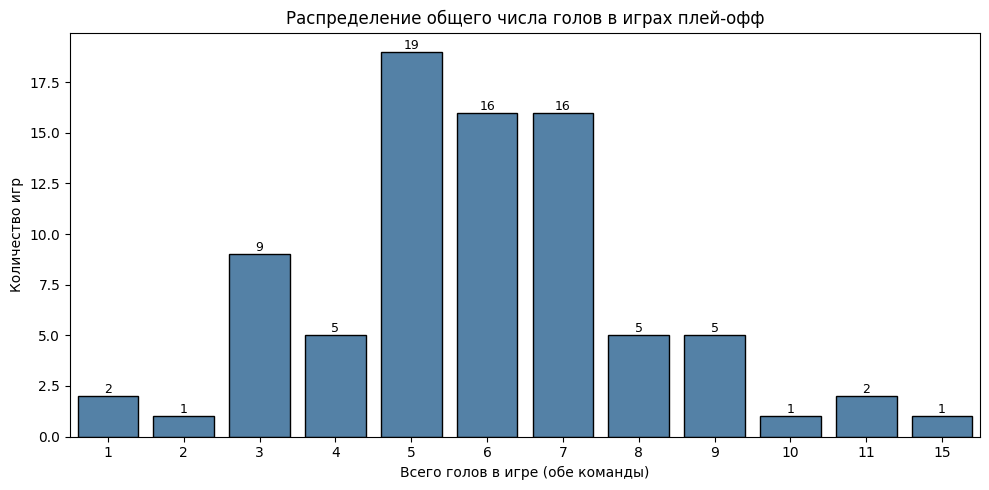

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=games,
    x="Total_Score",
    color="steelblue",
    edgecolor="black",
)

ax.set_title("Распределение общего числа голов в играх плей-офф")
ax.set_xlabel("Всего голов в игре (обе команды)")
ax.set_ylabel("Количество игр")

# подписи с частотой над столбцами
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(
            int(h),
            (p.get_x() + p.get_width() / 2, h),
            ha="center", va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.show()

около нормальное распределение, помним в среднем шесть голов, а мода пять. ну и слева более тяжелое распределение, меньше голов забить легче

### (6) самые результативные и нет игры

те игры с мин и макс числом голов

In [20]:
min_total = games["Total_Score"].min()
max_total = games["Total_Score"].max()

least_games = games[games["Total_Score"] == min_total].sort_index()
most_games  = games[games["Total_Score"] == max_total].sort_index()

least_list = [gameInfo(gid) for gid in least_games.index]
most_list  = [gameInfo(gid) for gid in most_games.index]

print("Самые нерезультативные:", least_list)
print("Самые результативные:  ", most_list)

Самые нерезультативные: ['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
Самые результативные:   ['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


### (7)

In [26]:
# столбцы с игроками на льду: по 6 слотов на каждую команду + вратари
player_cols = (
    [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
    + [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
    + ["Away Team's Goalie", "Home Team's Goalie"]
)

# длинный формат для подсчета уникальных потом: одна строка = (Game ID, игрок)
players_long = df.melt(
    id_vars="Game ID",
    value_vars=player_cols,
    value_name="Player"
)

player_counts = (
    players_long
    .groupby("Game ID")["Player"]
    .nunique()
    .reset_index(name="Player Count")
)

info = pd.DataFrame({
    "Game ID": games.index,
    "Game Info": [gameInfo(gid) for gid in games.index],
})

result = player_counts.merge(info, on="Game ID")

max_players = result["Player Count"].max()
top_games = (
    result[result["Player Count"] == max_players]
    .sort_values("Game ID")
    [["Game ID", "Game Info", "Player Count"]]
)

print(top_games)

       Game ID                                          Game Info  \
50  2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...   

    Player Count  
50            40  


### (8)

Теперь рассмотрите броски в створ ворот и прошедшие мимо ворот. Для каждого броска
сосчитайте расстояние до ворот. Для этого воспользуйтесь полями X Coordinate on the
Ice Rink и Y Coordinate on the Ice Rink для событий типа shot-on-goal, goal (точные
броски), missed-shot(неточные броски). Хоккейные ворота не являются точкой, а имеют
длину 6 футов, поэтому расстояние сосчитайте до ближайшей точки створа ворот (коор-
динаты тоже в футах, в метры ничего преобразовывать не нужно). Координата 𝑋 ворот
равняется 89 футов для ворот справа и −89 для ворот слева (см. рис. 2). Таким образом,


$$
d(x, y) = 
\left\{
\begin{aligned}
&\sqrt{(x - X)^2 + (y + 3)^2}, \text{если } y < -3,  \\
& |x - X|, \text{если } -3 \le y \le 3 \\
&\sqrt{(x - X)^2 + (y - 3)^2}, \text{если } y > 3
\end{aligned}
\right.
$$


Кроме того, обратите внимание на поле Home Team’s Defending Side. Если оно равно left,
то для бросков хозяев берите расстояние до правых ворот (𝑋 = 89), а для бросков гостей —
до левых ворот (𝑋 = −89). Если оно равно right, то наоборот. Понять, кто именно броса-
ет, хозяева или гости, можно сравнив значения полей Team Making the Playс Home Team,
например. Пример:

In [28]:
df["X Coordinate on the Ice Rink"]

0         NaN
1         0.0
2        95.0
3        49.0
4        95.0
         ... 
29705     0.0
29706   -33.0
29707    42.0
29708     NaN
29709     NaN
Name: X Coordinate on the Ice Rink, Length: 29710, dtype: float64

In [32]:
import numpy as np
events = df.copy()

x = pd.to_numeric(events["X Coordinate on the Ice Rink"], errors="coerce")
y = pd.to_numeric(events["Y Coordinate on the Ice Rink"], errors="coerce")

is_home = events["Team Making the Play"].eq(events["Home Team"])

# куда атакует бросающий
side = events["Home Team\'s Defending Side"].str.strip().str.lower()
home_attacks_right = side.eq("left")

x_goal = np.where(
    is_home,
    np.where(home_attacks_right,  89.0, -89.0),
    np.where(home_attacks_right, -89.0,  89.0),
)

dy = y - np.clip(y, -3, 3)
distance = np.sqrt((x - x_goal) ** 2 + dy ** 2)

events["Shot Length"] = distance

In [35]:
events[events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])][["Game ID", "Play Type", "Shot Length"]]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


### (9) распределение длины точных и неточных бросков

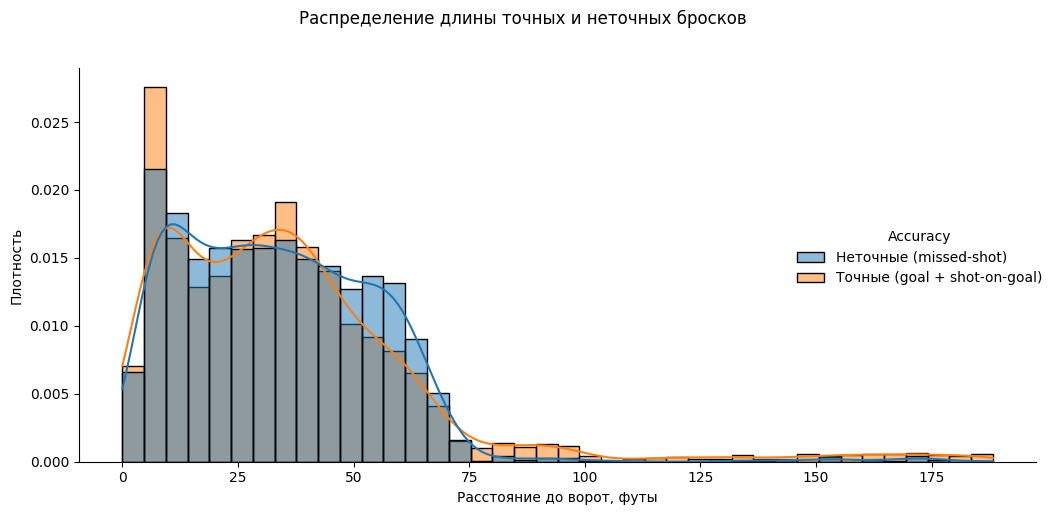

In [37]:
shots = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"]),
    ["Game ID", "Play Type", "Shot Length"],
].dropna(subset=["Shot Length"]).copy()

# точные (goal + shot-on-goal) и неточные (missed-shot)
shots["Accuracy"] = shots["Play Type"].map({
    "goal": "Точные (goal + shot-on-goal)",
    "shot-on-goal": "Точные (goal + shot-on-goal)",
    "missed-shot": "Неточные (missed-shot)",
})

g = sns.displot(
    data=shots,
    x="Shot Length",
    hue="Accuracy",
    stat="density",  
    common_norm=False,     # нормируем каждую группу, чтобы учесть размеры подвыборок
    bins=40,
    kde=True,
    height=5,
    aspect=1.6,
    alpha=0.5,
)
g.set_axis_labels("Расстояние до ворот, футы", "Плотность")
g.figure.suptitle("Распределение длины точных и неточных бросков", y=1.02)
plt.tight_layout()
plt.show()

видим что у неточных бросков рапсределение смещено вправо, те точные броски в среднем делаются с более близкой дистанции, что логично.  Длинный правый хвост точных бросков может объясняться геометрией - с дистанции 70–90 футов створ как бы узкий, и шайба чаще идёт именно в него, а не мимо, и особенностями записи событий

### (10) Сосчитайте долю точных бросков среди всех незаблокированных бросков у каждой команды в каждой игре. 

In [38]:
shot_types = ["goal", "shot-on-goal", "missed-shot"] # незаблок
shots = events[events["Play Type"].isin(shot_types)].copy()
shots["Is Accurate"] = shots["Play Type"].isin(["goal", "shot-on-goal"])

numshots = (
    shots
    .groupby(["Game ID", "Team Making the Play"])["Is Accurate"]
    .mean()
    .rename("Share of Shots on Goal")
)

print(numshots.head())
print(numshots.describe())

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
Name: Share of Shots on Goal, dtype: float64
count    164.000000
mean       0.639150
std        0.085000
min        0.352941
25%        0.582955
50%        0.638889
75%        0.688889
max        0.860465
Name: Share of Shots on Goal, dtype: float64


Доля точных бросков среди незаблокированных составляет в среднем около 0.63, но заметно варьируется — от 0.45 до 0.80 — как между играми, так и между командами в одной игре. Из-за небольшого числа бросков в отдельной игре (20–40) доля точных бросков за один матч — немного шумная метрика, и для устойчивых сравнений её стоит агрегировать по нескольким играм

### (11) Найдите и выведите по пять команд с самыми высокими и самыми низкими средними долями точных бросков за матч. 

In [39]:
avgnumshots = (
    numshots
    .groupby("Team Making the Play")
    .mean()
    .sort_values(ascending=False)
)

print("Топ-5 по средней доле точных бросков:")
print(avgnumshots.nlargest(5))

print("\nАнти-топ-5:")
print(avgnumshots.nsmallest(5))

Топ-5 по средней доле точных бросков:
Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

Анти-топ-5:
Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64


Средняя доля точных бросков среди незаблокированных варьируется по командам примерно от 0.55 (Pittsburgh) до 0.71 (Edmonton) — разброс около 15 пп. Заметим что метрика отражает стиль бросковой активности, а не результативность: для оценки эффективности атаки её нужно рассматривать вместе с объёмом бросков и конверсией голов.

### (12) Сосчитайте среднее число бросков в створ ворот и среднее число голов за игру для каждой из 16 команд-участниц плей-офф.

In [41]:
team_games = pd.concat(
    [
        df[["Game ID", "Home Team"]].rename(columns={"Home Team": "Team"}),
        df[["Game ID", "Away Team"]].rename(columns={"Away Team": "Team"}),
    ],
    ignore_index=True,
).drop_duplicates()

counts = (
    df[df["Play Type"].isin(["shot-on-goal", "goal"])]
    .groupby(["Team Making the Play", "Game ID", "Play Type"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["shot-on-goal", "goal"], fill_value=0)
    .rename(columns={"shot-on-goal": "SOG_events", "goal": "Goals"})
)

counts = (
    team_games.set_index(["Team", "Game ID"])
    .join(counts)
    .fillna(0)
)

summary = (
    counts.groupby("Team")[["SOG_events", "Goals"]]
    .mean()
    .rename(columns={
        "SOG_events": "Avg Shots on Goal",
        "Goals": "Avg Goals",
    })
)

print(summary.sort_values("Avg Goals", ascending=False))

                      Avg Shots on Goal  Avg Goals
Team                                              
Edmonton Oilers               26.416667   3.916667
Minnesota Wild                26.909091   3.636364
Utah Mammoth                  25.833333   3.416667
Anaheim Ducks                 25.625000   3.375000
Dallas Stars                  27.500000   3.166667
Buffalo Sabres                25.461538   3.153846
Vegas Golden Knights          24.704545   3.136364
Colorado Avalanche            25.923077   3.115385
Montréal Canadiens            23.710526   2.894737
Carolina Hurricanes           24.684211   2.763158
Boston Bruins                 25.750000   2.666667
Los Angeles Kings             25.750000   2.250000
Philadelphia Flyers           24.800000   2.250000
Pittsburgh Penguins           23.916667   2.250000
Tampa Bay Lightning           22.928571   2.214286
Ottawa Senators               28.625000   2.000000


### (13) нарисуйте регрессионную диаграмму (функция seaborn.regplot()), показывающую, есть ли связь между средним числом бросков в створ ворот и средним числом забитых шайб 

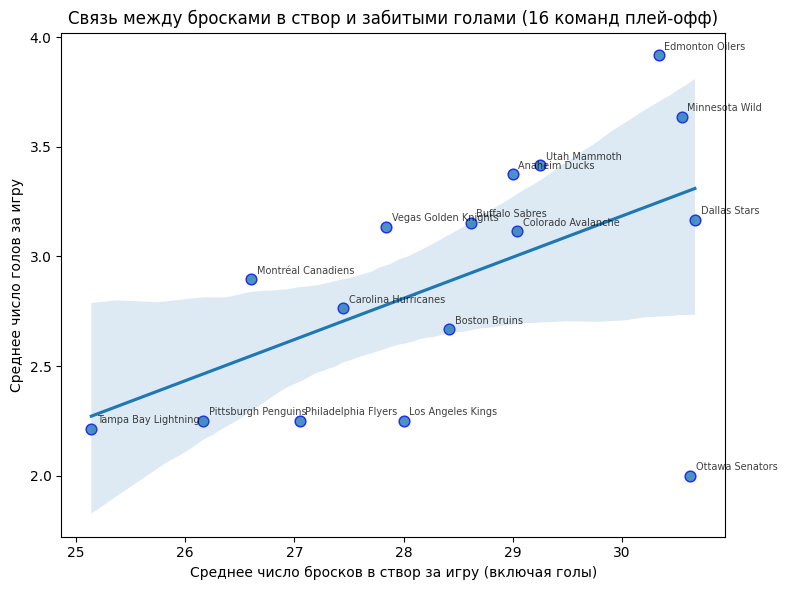

In [44]:
summary["SOG incl. goals"] = summary["Avg Shots on Goal"] + summary["Avg Goals"]

plt.figure(figsize=(8, 6))
ax = sns.regplot(
    data=summary,
    x="SOG incl. goals",
    y="Avg Goals",
    ci=95,         
    scatter_kws={"s": 60, "alpha": 0.8, "edgecolor": "blue"})

for team, row in summary.iterrows():
    ax.annotate(
        team,
        (row["SOG incl. goals"], row["Avg Goals"]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
        alpha=0.75,
    )

ax.set_xlabel("Среднее число бросков в створ за игру (включая голы)")
ax.set_ylabel("Среднее число голов за игру")
ax.set_title("Связь между бросками в створ и забитыми голами (16 команд плей-офф)")

plt.tight_layout()
plt.show()

Между средним числом бросков в створ и средним числом голов за игру есть умеренная положительная связь, есть результаты в доверительном интервале: команды с большим объемом бросков в створ в среднем забивают больше. однако разброс точек вокруг линии регрессии довольно большой. Это говорит о том, что важен не только объем, но и качество бросков (позиция, трафик, пустые ворота) и игра вратаря соперника

### (14) Найдите матч, в котором было совершено больше всего ударов по воротам (считайте все удары, включая промахи и заблокированные blocked-shot).

In [45]:
shot_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]

shots = df[df["Play Type"].isin(shot_types)]

shots_per_game = shots.groupby("Game ID").size()

idxmax = shots_per_game.idxmax()

print("Game ID:", idxmax)
print("Всего бросков (включая blocked-shot):", shots_per_game.loc[idxmax])
print(gameInfo(idxmax))

Game ID: 2025030132
Всего бросков (включая blocked-shot): 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


### (15) диаграмма рассеивания катка

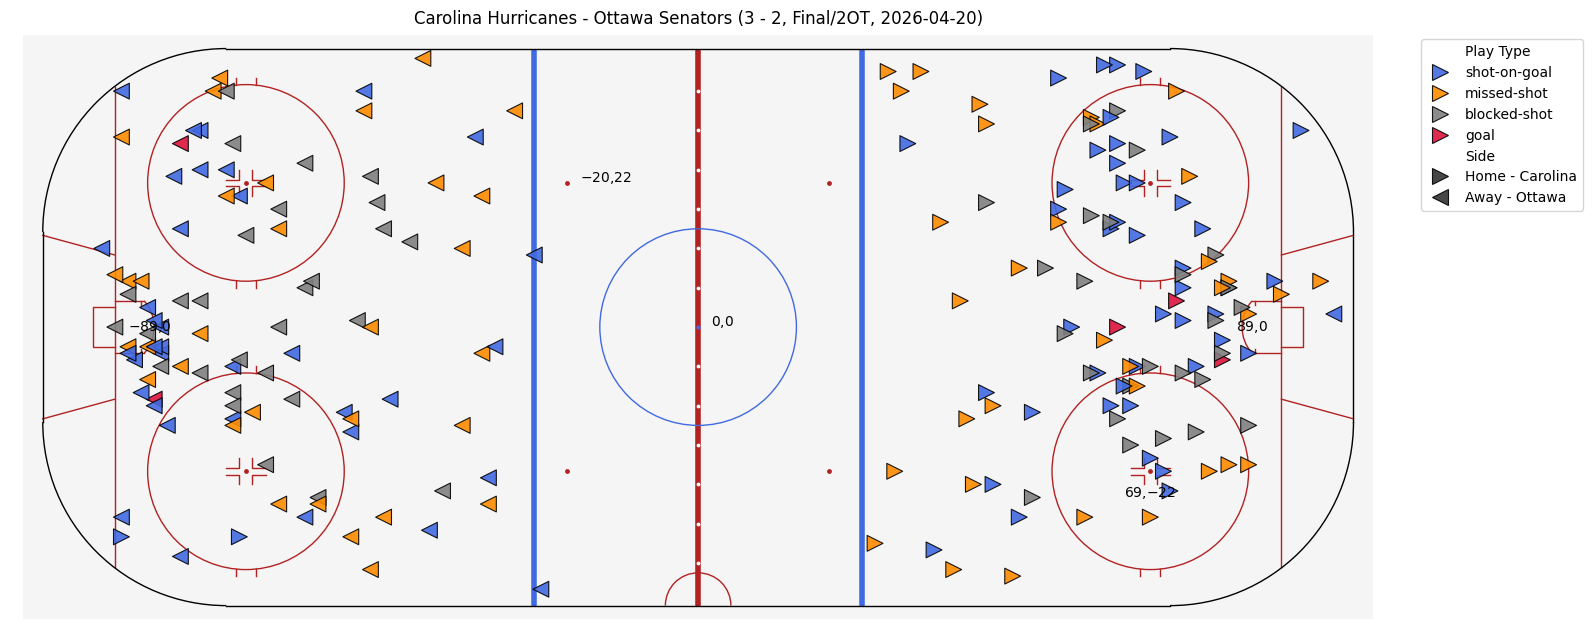

In [58]:
from rink import plot_rink

game_id = 2025030132  # Carolina Hurricanes - Ottawa Senators, 3:2 Final/2OT

shot_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]

shots = df[
    (df["Game ID"] == game_id) &
    (df["Play Type"].isin(shot_types))
].copy()

shots = shots.dropna(subset=[
    "X Coordinate on the Ice Rink",
    "Y Coordinate on the Ice Rink",
    "Home Team's Defending Side",
])

shots["x"] = pd.to_numeric(shots["X Coordinate on the Ice Rink"], errors="coerce")
shots["y"] = pd.to_numeric(shots["Y Coordinate on the Ice Rink"], errors="coerce")

flip = shots["Home Team's Defending Side"].str.strip().str.lower() == "right"
shots.loc[flip, "x"] = -shots.loc[flip, "x"]
shots.loc[flip, "y"] = -shots.loc[flip, "y"]

shots["Side"] = np.where(
    shots["Team Making the Play"] == shots["Home Team"],
    "Home - Carolina",
    "Away - Ottawa",
)

fig, ax = plt.subplots(figsize=(16, 8))
plot_rink(True)

sns.scatterplot(
    data=shots,
    x="x",
    y="y",
    hue="Play Type",
    style="Side",
    markers={
        "Home - Carolina": ">",   # треугольник, «смотрит» на правые ворота
        "Away - Ottawa":  "<",   # треугольник, «смотрит» на левые ворота
    },
    palette={
        "goal":          "crimson",
        "shot-on-goal":  "royalblue",
        "missed-shot":   "darkorange",
        "blocked-shot":  "gray",
    },
    s=130,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    ax=ax,
)

ax.set_xlim(-105, 105)
ax.set_ylim(-45, 45)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(gameInfo(game_id))

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=True)

plt.tight_layout()
plt.show()

### (16) Выведите список из десяти игроков, которые забили больше всех голов в плейофф (поле Player in the Event #1для Play Type, равного goal).

In [52]:
df.loc[df["Play Type"] == "goal", "Player in the Event #1"].dropna().value_counts().head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

### (17) больше всего голевых передач в плейофф

In [53]:
goals = df[df["Play Type"].eq("goal")].copy()

assists = pd.concat(
    [goals["Player in the Event #2"], goals["Player in the Event #3"]],
    ignore_index=True,
).dropna()

top_assists = (
    assists
    .value_counts()
    .head(10)
    .rename_axis("Player")
    .to_frame("Assists")
)

print(top_assists)

                 Assists
Player                  
Jack Eichel           20
Mitch Marner          19
Lane Hutson           13
Jackson Blake         13
Nick Suzuki           12
Taylor Hall           12
Martin Necas          12
Shea Theodore         12
Kirill Kaprizov       11
Quinn Hughes          11


### (18) Выведите список из десяти игроков, которые набрали больше всего очков по системе гол плюс пас.

In [54]:
goals = df[df["Play Type"].eq("goal")]

goal_counts = goals["Player in the Event #1"].dropna().value_counts()
assist_counts = (
    pd.concat([goals["Player in the Event #2"], goals["Player in the Event #3"]])
      .dropna()
      .value_counts()
)

points = (
    goal_counts.add(assist_counts, fill_value=0)
    .astype(int)
    .sort_values(ascending=False)
)
top10_points = points.head(10).rename_axis("Player").to_frame("Points")
print(top10_points)

                 Points
Player                 
Mitch Marner         29
Jack Eichel          22
Jackson Blake        20
Taylor Hall          19
Brett Howden         18
Nikolaj Ehlers       18
Shea Theodore        18
Pavel Dorofeyev      16
Lane Hutson          16
Logan Stankoven      16


### (19)
Выведите список из десяти игроков, которые в среднем нанесли больше всего бросков
в створ ворот за одну игру.

In [56]:
ice_cols = (
    [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
    + [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
    + ["Away Team's Goalie", "Home Team's Goalie"]
)

long_ice = df.melt(id_vars="Game ID", value_vars=ice_cols, value_name="Player").dropna()
long_ice = long_ice[long_ice["Player"].astype(str).str.strip() != ""]

games_played = long_ice.groupby("Player")["Game ID"].nunique()

In [57]:
sog = df[df["Play Type"].isin(["shot-on-goal", "goal"])]   # «в створ» = SOG + голы
sog_counts = sog["Player in the Event #1"].dropna().value_counts()

avg_sog = (
    (sog_counts / games_played.reindex(sog_counts.index))
    .dropna()
    .sort_values(ascending=False)
)
top10_sog = avg_sog.head(10).rename_axis("Player").to_frame("Avg Shots on Goal per Game")
print(top10_sog)

                  Avg Shots on Goal per Game
Player                                      
Jason Robertson                     5.000000
Dylan Guenther                      4.500000
Nikita Kucherov                     4.428571
Matt Boldy                          4.363636
Quinton Byfield                     4.250000
Darren Raddysh                      4.000000
Joel Eriksson Ek                    4.000000
Alex Laferriere                     3.750000
David Pastrnak                      3.666667
Nathan MacKinnon                    3.615385


### (20) ср число приемов за игру

In [59]:
hits = df[df["Play Type"].eq("hit")]["Player in the Event #1"].dropna().value_counts()

avg_hits = (
    (hits / games_played.reindex(hits.index))
    .dropna()
    .sort_values(ascending=False)
)
top10_hits = avg_hits.head(10).rename_axis("Player").to_frame("Avg Hits per Game")
print(top10_hits)

                    Avg Hits per Game
Player                               
Lawson Crouse                6.333333
Alexander Petrovic           6.000000
Alex Turcotte                6.000000
Yakov Trenin                 5.666667
Dylan Cozens                 5.500000
Vasily Podkolzin             5.333333
Ivan Barbashev               5.000000
Carl Grundstrom              5.000000
Marcus Foligno               5.000000
Owen Tippett                 4.833333


### (21) вратари с сухой игрой

In [60]:
goals = df[df["Play Type"].eq("goal")].copy()

# кто пропустил: вратарь противоположной команды
home_scored = goals["Team Making the Play"].eq(goals["Home Team"])
goals["Conceding Goalie"] = np.where(
    home_scored,
    goals["Away Team's Goalie"],
    goals["Home Team's Goalie"],
)

# пропущенные голы по (вратарь, игра)
conceded = (
    goals.dropna(subset=["Conceding Goalie"])
         .groupby(["Conceding Goalie", "Game ID"])
         .size()
         .rename("Goals Conceded")
)

goalie_long = (
    df.melt(id_vars="Game ID",
            value_vars=["Away Team's Goalie", "Home Team's Goalie"],
            value_name="Goalie")
      .dropna()
)
goalie_long = goalie_long[goalie_long["Goalie"].astype(str).str.strip() != ""]
goalie_games = goalie_long.drop_duplicates().set_index(["Goalie", "Game ID"])

goalie_games = goalie_games.join(conceded, how="left").fillna({"Goals Conceded": 0})

shutout_games = goalie_games[goalie_games["Goals Conceded"].eq(0)]

shutout_goalies = sorted(shutout_games.index.get_level_values("Goalie").unique())
print(shutout_goalies)

print(shutout_games)

['Andrei Vasilevskiy', 'Arturs Silovs', 'Dan Vladar', 'Jakub Dobes']
                                                          variable  \
Goalie             Game ID    Conceding Goalie                       
Andrei Vasilevskiy 2025030126 nan               Away Team's Goalie   
Arturs Silovs      2025030146 nan               Away Team's Goalie   
Jakub Dobes        2025030126 nan               Home Team's Goalie   
Dan Vladar         2025030146 nan               Home Team's Goalie   

                                                Goals Conceded  
Goalie             Game ID    Conceding Goalie                  
Andrei Vasilevskiy 2025030126 nan                          0.0  
Arturs Silovs      2025030146 nan                          0.0  
Jakub Dobes        2025030126 nan                          0.0  
Dan Vladar         2025030146 nan                          0.0  


### (22)

интересно проверить, есть ли такое, что команда, которая забивает первый гол, в итоге выигрывает. можем просто посмотреть долю таких игр

In [64]:
# первые голы
first_goals = (
    df[df["Play Type"] == "goal"]
      .sort_values(["Game ID", "Play ID"])
      .groupby("Game ID", as_index=False)
      .head(1)
      .set_index("Game ID")["Team Making the Play"]
      .rename("First_Scorer")
)

result = first_goals.to_frame().join(
    games[["Home_Team", "Away_Team", "Home_Score", "Away_Score", "Outcome"]]
)

result["Winner"] = np.where(
    result["Home_Score"] > result["Away_Score"],
    result["Home_Team"],
    result["Away_Team"],
)

# cовпал ли первый гол с победителем
result["First_Scorer_Won"] = result["First_Scorer"] == result["Winner"]

n = len(result)
wins = result["First_Scorer_Won"].sum()
print(f"Игр: {n}, побед команды, забившей первой: {wins} ({wins/n:.1%})")

Игр: 82, побед команды, забившей первой: 56 (68.3%)


да, таких игр больше. демотивируют противника сразу